In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, models
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import os
import wandb
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import gc
import cv2

# Initialize Weights & Biases
wandb.init(project="face-recognition-resnet-scratch")
wandb.login(key="c02566a740b6ae5bd072dcf4ae32d9f735e9fa0b")
from google.colab import files
uploaded = files.upload()
if list(uploaded.keys())[0].endswith('.zip'):
    !unzip -q "{list(uploaded.keys())[0]}"  # Unzips to current directory
    print(f"Files unzipped: {os.listdir()}")
else:
    print("Assuming files are already in place.")

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


Using device: cuda


In [ ]:
class FaceDataset(Dataset):
    def __init__(self, root_dir, transform=None, is_test=False):
        self.root_dir = root_dir
        self.transform = transform
        self.is_test = is_test  # Flag for test set

        if not self.is_test:
            # For train/val - use class folders
            self.classes = ['class_0', 'class_1']
            self.image_paths = []
            self.labels = []

            for class_idx, class_name in enumerate(self.classes):
                class_dir = os.path.join(root_dir, class_name)
                if os.path.exists(class_dir):  # Check if directory exists
                    for img_name in os.listdir(class_dir):
                        self.image_paths.append(os.path.join(class_dir, img_name))
                        self.labels.append(class_idx)
        else:
            # For test - all images in root_dir
            self.image_paths = []
            self.labels = []  # Will be empty for test if no labels

            if os.path.exists(root_dir):
                for img_name in os.listdir(root_dir):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(root_dir, img_name))
                        # If you have test labels, add them here
                        # self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if not self.is_test:
            label = self.labels[idx]
        else:
            label = -1  # Or implement your test label logic

        if self.transform:
            image = self.transform(image)

        return image, label

# Define transformations with augmentations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets (modify test dataset creation)
train_dataset = FaceDataset('final/train', transform=train_transform)
val_dataset = FaceDataset('final/val', transform=val_test_transform)
test_dataset = FaceDataset('final/test', transform=val_test_transform, is_test=True)

batch_size = 32  # Adjust based on GPU memory
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
def get_resnet_scratch():
    model = models.resnet18(pretrained=False)
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 2)
    return model.to(device)

In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Initialize model
model = get_resnet_scratch()

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(),
                     lr=0.1,  # Higher LR for scratch training
                     momentum=0.9,
                     weight_decay=1e-4)

# Learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

In [ ]:
def train_model(model, train_loader, val_loader, epochs=50):
    best_val_acc = 0.0

    for epoch in range(epochs):
        # Training Phase
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = 100 * correct / total
        train_loss_avg = train_loss / len(train_loader)

        # Validation Phase
        val_loss, val_acc = validate(model, val_loader, criterion)

        # Update LR scheduler
        scheduler.step(val_loss)

        # Log metrics to wandb
        wandb.log({
            "epoch": epoch + 1,
            "train_loss": train_loss_avg,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": optimizer.param_groups[0]['lr']
        })

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_scratch.pth')

        print(f'Epoch {epoch+1}/{epochs} | '
              f'Train Loss: {train_loss/len(train_loader):.4f} | '
              f'Train Acc: {train_acc:.2f}% | '
              f'Val Loss: {val_loss:.4f} | '
              f'Val Acc: {val_acc:.2f}%')

def validate(model, val_loader, criterion):
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return val_loss/len(val_loader), 100 * correct / total

In [ ]:
train_model(model, train_loader, val_loader, epochs=10)

Epoch 1/10 | Train Loss: 2.5349 | Train Acc: 62.07% | Val Loss: 49.7795 | Val Acc: 61.39%
Epoch 2/10 | Train Loss: 0.9936 | Train Acc: 66.41% | Val Loss: 2.8399 | Val Acc: 47.52%
Epoch 3/10 | Train Loss: 0.6704 | Train Acc: 72.54% | Val Loss: 1.3724 | Val Acc: 45.54%
Epoch 4/10 | Train Loss: 0.6481 | Train Acc: 70.88% | Val Loss: 0.5249 | Val Acc: 77.23%
Epoch 5/10 | Train Loss: 0.4594 | Train Acc: 79.05% | Val Loss: 1.2970 | Val Acc: 57.43%
Epoch 6/10 | Train Loss: 0.4124 | Train Acc: 83.14% | Val Loss: 0.2829 | Val Acc: 89.11%
Epoch 7/10 | Train Loss: 0.3033 | Train Acc: 87.87% | Val Loss: 0.2030 | Val Acc: 89.11%
Epoch 8/10 | Train Loss: 0.2391 | Train Acc: 91.06% | Val Loss: 0.2195 | Val Acc: 86.14%
Epoch 9/10 | Train Loss: 0.2409 | Train Acc: 90.68% | Val Loss: 0.0759 | Val Acc: 97.03%
Epoch 10/10 | Train Loss: 0.3105 | Train Acc: 88.51% | Val Loss: 1.3493 | Val Acc: 59.41%


In [ ]:
import pandas as pd
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # If test images are in class folders (class_0, class_1)
        if os.path.exists(os.path.join(root_dir, 'class_0')):
            for class_idx, class_name in enumerate(['class_0', 'class_1']):
                class_dir = os.path.join(root_dir, class_name)
                for img_name in os.listdir(class_dir):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(class_dir, img_name))
                        self.labels.append(class_idx)
        # If using a CSV with labels
        elif os.path.exists('test_labels.csv'):
            df = pd.read_csv('test_labels.csv')
            self.image_paths = [os.path.join(root_dir, f) for f in df['image_path']]
            self.labels = df['label'].values
        else:
            raise ValueError("No test labels found!")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, self.labels[idx], img_path  # Now returns (image, label, path)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, test_loader):
    model.eval()
    all_labels = []
    all_preds = []
    image_paths = []

    with torch.no_grad():
        for inputs, labels, paths in test_loader:  # Modified to unpack 3 values
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            image_paths.extend(paths)

    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)

    # Log test metrics to wandb
    wandb.log({
        "test_accuracy": accuracy,
        "test_precision": precision,
        "test_recall": recall,
        "test_f1_score": f1
    })

    print("\nTest Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not You', 'You'],
                yticklabels=['Not You', 'You'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

    # Log confusion matrix to wandb
    wandb.log({"confusion_matrix": wandb.Image(plt)})
    plt.show()
    plt.close()

    # Save predictions with true labels
    results = pd.DataFrame({
        'image_path': image_paths,
        'true_label': all_labels,
        'prediction': all_preds
    })
    results.to_csv('test_results_with_metrics.csv', index=False)

    return accuracy

In [ ]:
import cv2
import numpy as np

def generate_prediction_video(test_loader, model, class_names=['Not You', 'You'], output_path='output_video.mp4', max_frames=50):
    model.eval()
    images = []
    preds = []
    truths = []

    # Collect images, predictions, and true labels
    with torch.no_grad():
        for inputs, labels, _ in test_loader:  # Unpack inputs, labels, paths
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            images.extend(inputs.cpu().numpy())  # Store images
            preds.extend(predicted.cpu().numpy())  # Store predictions
            truths.extend(labels.cpu().numpy())  # Store true labels

    # Initialize video writer
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), 2, (224, 224))

    # Process up to max_frames
    for i in range(min(len(images), max_frames)):
        # Denormalize image
        img = images[i].transpose(1, 2, 0)  # Change from (C, H, W) to (H, W, C)
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Reverse normalization
        img = np.clip(img * 255, 0, 255).astype(np.uint8)  # Scale to 0-255 and convert to uint8
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # Convert to BGR for OpenCV

        # Add prediction and true label text
        cv2.putText(img, f"Pred: {class_names[preds[i]]}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        cv2.putText(img, f"True: {class_names[truths[i]]}", (10, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

        # Write frame to video
        out.write(img)

    # Release video writer
    out.release()
    print(f"Video saved to {output_path}")


Test Metrics:
Accuracy: 0.8750
Precision: 0.8750
Recall: 0.8235
F1-Score: 0.8485


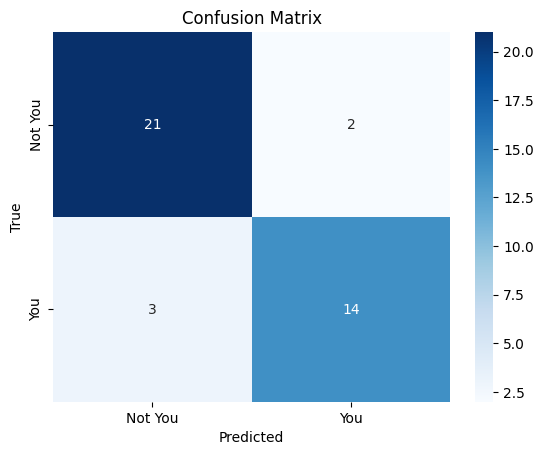

<Figure size 640x480 with 0 Axes>

Video saved to face_recognition_output.mp4


epoch,▁▂▃▃▄▅▆▆▇█
learning_rate,▁▁▁▁▁▁▁▁▁▁
test_accuracy,▁
test_f1_score,▁
test_precision,▁
test_recall,▁
train_accuracy,▁▂▄▃▅▆▇██▇
train_loss,█▃▂▂▂▂▁▁▁▁
val_accuracy,▃▁▁▅▃▇▇▇█▃
val_loss,█▁▁▁▁▁▁▁▁▁
epoch,10


In [ ]:
# Create test dataset (now with labels)
test_dataset = TestDataset('final/test', transform=val_test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Load trained model
model.load_state_dict(torch.load('best_resnet_scratch.pth'))
model.to(device)

# Run evaluation
test_accuracy = evaluate_model(model, test_loader)
# Generate prediction video
generate_prediction_video(test_loader, model, class_names=['Not You', 'You'],
                         output_path='face_recognition_output.mp4', max_frames=50)

# Finish wandb run
wandb.finish()

In [ ]:
# def get_resnet_pretrained():
#     model = models.resnet18(pretrained=True)
#     num_features = model.fc.in_features
#     model.fc = nn.Linear(num_features, 2)
#     return model.to(device)

wandb.init(project="face-recognition-resnet-pretrained")
wandb.login(key="c02566a740b6ae5bd072dcf4ae32d9f735e9fa0b")

def get_resnet_pretrained(freeze=True):
    model = models.resnet18(pretrained=True)
    if freeze:
        for param in model.parameters():
            param.requires_grad = False
        # Unfreeze final layer
        for param in model.fc.parameters():
            param.requires_grad = True
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 2)
    return model.to(device)


wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Initialize model
model = get_resnet_pretrained(freeze=False)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(),
                     lr=0.1,  # Higher LR for scratch training
                     momentum=0.9,
                     weight_decay=1e-4)

# Learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


In [ ]:
def train_model(model, train_loader, val_loader, epochs=50):
    best_val_acc = 0.0

    for epoch in range(epochs):
        # Training Phase
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = 100 * correct / total
        train_loss_avg = train_loss / len(train_loader)
        # Validation Phase
        val_loss, val_acc = validate(model, val_loader, criterion)

        # Update LR scheduler
        scheduler.step(val_loss)

        # Log metrics to wandb
        wandb.log({
            "epoch": epoch + 1,
            "train_loss": train_loss_avg,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": optimizer.param_groups[0]['lr']
        })

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_pretrained.pth')

        print(f'Epoch {epoch+1}/{epochs} | '
              f'Train Loss: {train_loss/len(train_loader):.4f} | '
              f'Train Acc: {train_acc:.2f}% | '
              f'Val Loss: {val_loss:.4f} | '
              f'Val Acc: {val_acc:.2f}%')

def validate(model, val_loader, criterion):
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return val_loss/len(val_loader), 100 * correct / total

In [ ]:
train_model(model, train_loader, val_loader, epochs=10)

Epoch 1/10 | Train Loss: 4.9921 | Train Acc: 59.51% | Val Loss: 1009.1649 | Val Acc: 43.56%
Epoch 2/10 | Train Loss: 2.7674 | Train Acc: 66.67% | Val Loss: 2.9972 | Val Acc: 71.29%
Epoch 3/10 | Train Loss: 0.5323 | Train Acc: 87.23% | Val Loss: 0.2461 | Val Acc: 91.09%
Epoch 4/10 | Train Loss: 0.3990 | Train Acc: 84.42% | Val Loss: 0.9962 | Val Acc: 74.26%
Epoch 5/10 | Train Loss: 0.3464 | Train Acc: 86.21% | Val Loss: 0.1247 | Val Acc: 91.09%
Epoch 6/10 | Train Loss: 0.2488 | Train Acc: 89.78% | Val Loss: 0.1668 | Val Acc: 94.06%
Epoch 7/10 | Train Loss: 0.1523 | Train Acc: 94.51% | Val Loss: 0.0192 | Val Acc: 98.02%
Epoch 8/10 | Train Loss: 0.1401 | Train Acc: 95.66% | Val Loss: 0.0950 | Val Acc: 97.03%
Epoch 9/10 | Train Loss: 0.1157 | Train Acc: 95.53% | Val Loss: 0.0105 | Val Acc: 100.00%
Epoch 10/10 | Train Loss: 0.1137 | Train Acc: 96.30% | Val Loss: 0.0289 | Val Acc: 99.01%


In [ ]:
import pandas as pd
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # If test images are in class folders (class_0, class_1)
        if os.path.exists(os.path.join(root_dir, 'class_0')):
            for class_idx, class_name in enumerate(['class_0', 'class_1']):
                class_dir = os.path.join(root_dir, class_name)
                for img_name in os.listdir(class_dir):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(class_dir, img_name))
                        self.labels.append(class_idx)
        # If using a CSV with labels
        elif os.path.exists('test_labels.csv'):
            df = pd.read_csv('test_labels.csv')
            self.image_paths = [os.path.join(root_dir, f) for f in df['image_path']]
            self.labels = df['label'].values
        else:
            raise ValueError("No test labels found!")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, self.labels[idx], img_path  # Now returns (image, label, path)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, test_loader):
    model.eval()
    all_labels = []
    all_preds = []
    image_paths = []

    with torch.no_grad():
        for inputs, labels, paths in test_loader:  # Modified to unpack 3 values
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            image_paths.extend(paths)

    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)

    # Log test metrics to wandb
    wandb.log({
        "test_accuracy": accuracy,
        "test_precision": precision,
        "test_recall": recall,
        "test_f1_score": f1
    })

    print("\nTest Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not You', 'You'],
                yticklabels=['Not You', 'You'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

    # Log confusion matrix to wandb
    wandb.log({"confusion_matrix": wandb.Image(plt)})
    plt.show()
    plt.close()

    # Save predictions with true labels
    results = pd.DataFrame({
        'image_path': image_paths,
        'true_label': all_labels,
        'prediction': all_preds
    })
    results.to_csv('test_results_with_metrics.csv', index=False)

    return accuracy

In [ ]:
import cv2
import numpy as np

def generate_prediction_video(test_loader, model, class_names=['Not You', 'You'], output_path='output_video.mp4', max_frames=50):
    model.eval()
    images = []
    preds = []
    truths = []

    # Collect images, predictions, and true labels
    with torch.no_grad():
        for inputs, labels, _ in test_loader:  # Unpack inputs, labels, paths
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            images.extend(inputs.cpu().numpy())  # Store images
            preds.extend(predicted.cpu().numpy())  # Store predictions
            truths.extend(labels.cpu().numpy())  # Store true labels

    # Initialize video writer
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), 2, (224, 224))

    # Process up to max_frames
    for i in range(min(len(images), max_frames)):
        # Denormalize image
        img = images[i].transpose(1, 2, 0)  # Change from (C, H, W) to (H, W, C)
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Reverse normalization
        img = np.clip(img * 255, 0, 255).astype(np.uint8)  # Scale to 0-255 and convert to uint8
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # Convert to BGR for OpenCV

        # Add prediction and true label text
        cv2.putText(img, f"Pred: {class_names[preds[i]]}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        cv2.putText(img, f"True: {class_names[truths[i]]}", (10, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

        # Write frame to video
        out.write(img)

    # Release video writer
    out.release()
    print(f"Video saved to {output_path}")


Test Metrics:
Accuracy: 0.8750
Precision: 0.7727
Recall: 1.0000
F1-Score: 0.8718


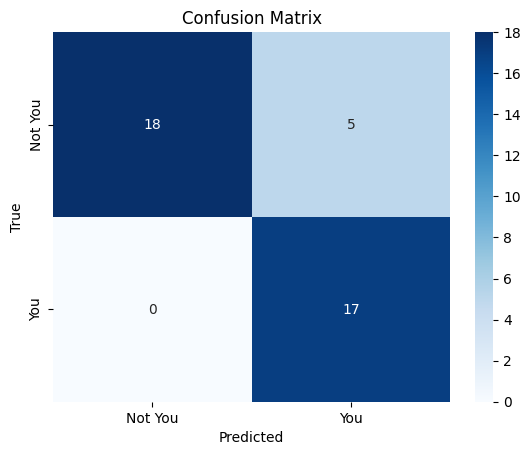

<Figure size 640x480 with 0 Axes>

Video saved to face_recognition_output_resnet_pretrained.mp4


epoch,▁▂▃▃▄▅▆▆▇█
learning_rate,▁▁▁▁▁▁▁▁▁▁
test_accuracy,▁
test_f1_score,▁
test_precision,▁
test_recall,▁
train_accuracy,▁▂▆▆▆▇████
train_loss,█▅▂▁▁▁▁▁▁▁
val_accuracy,▁▄▇▅▇▇████
val_loss,█▁▁▁▁▁▁▁▁▁
epoch,10


In [ ]:
# Create test dataset (now with labels)
test_dataset = TestDataset('final/test', transform=val_test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Load trained model
model.load_state_dict(torch.load('best_resnet_pretrained.pth'))
model.to(device)

# Run evaluation
test_accuracy = evaluate_model(model, test_loader)
# Generate prediction video
generate_prediction_video(test_loader, model, class_names=['Not You', 'You'],
                         output_path='face_recognition_output_resnet_pretrained.mp4', max_frames=50)
wandb.finish()

Dataset - https://drive.google.com/file/d/17a3TAZT-_s08FBGRpCAGwnmIbZgwjlMq/view?usp=drive_link